# P06: a pretrained ResNet-18 (transfer learning)

ADR 0009: our small CNNs reach about 58 to 59% on validation and cannot go further, because 1,920 training images are too few
to learn good features from scratch. **Transfer learning** starts from a network already trained on ImageNet (1.2 million
photographs, 1,000 categories): its early layers detect edges, textures and shapes that are useful for almost any image.

We use ResNet-18 from torchvision, with its ImageNet weights, in two stages:

| stage | what is trained | trainable weights |
|---|---|---|
| 1. **feature extraction** (`finetune: "head"`) | only a new final layer (512 features to 5 genres); the rest of the ResNet is frozen | 2,565 |
| 2. **fine-tuning** (`finetune: "layer4"`) | the last block of the ResNet (`layer4`) and the new final layer, with a small learning rate | about 8.4 million |

The frozen part is never trained, so every image is passed through it **once** and its output is kept. Training then only touches
the small trainable part, which makes stage 1 almost instant. Details that matter:

- images are 224 x 224 and standardised with the **ImageNet** mean and std (what the pretrained network expects);
- no data augmentation (it would break the "compute once" trick, and `fit` has no augmentation yet);
- "weights" below means *trainable* weights; the time reported by `run_experiment` does not include computing the frozen features;
- **caution when comparing with the CNNs:** the ResNet works at 224 px, our CNNs at 64 px. A gain mixes the effect of
  pretraining and the effect of resolution.

**The test set (museum B) is not used here** (ADR 0003).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision

from deep_learning_project_waerniers_lamy.vision.utils import (
    add_test_score, build_resnet_head, load_resnet_data, load_result, run_experiment, summary, pretrained_resnet)

BASE = {
    "model": "resnet18",
    "image_size": 224,
    "dropout": 0.0,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
}
HEAD = {**BASE, "finetune": "head", "epochs": 30, "lr": 1e-3}
LAYER4 = {**BASE, "finetune": "layer4", "epochs": 8, "lr": 1e-4}

runs_table = summary()


def saved_run(name):
    """The earliest saved run with this name."""
    rows = runs_table[runs_table["name"] == name].sort_values("date")
    return load_result(rows["file"].iloc[0])


cnn_longer = saved_run("cnn_longer")  # our best small CNN, for comparison

## 1. Do the pretrained weights and our preprocessing work?

A quick check before training anything: we give our validation images to the *original* ResNet, with its ImageNet classifier,
and look at the ImageNet categories it guesses. If the weights and the preprocessing are right, the guesses should be
plausible (a church-like building for a cityscape, a valley for a landscape...), even though ImageNet does not know our genres.

In [2]:
categories = torchvision.models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
check = load_resnet_data(HEAD, splits=("val",))  # 512 features per validation image
with torch.no_grad():
    guesses = pretrained_resnet().fc(check["X_val"]).argmax(dim=1)  # the original ImageNet classifier

for genre_id, genre in enumerate(check["classes"]):
    in_genre = guesses[check["y_val"] == genre_id]
    top = torch.bincount(in_genre).topk(3)
    print(f"{genre:19s}", [(categories[i], int(n)) for n, i in zip(top.values, top.indices)])

cityscape           [('monastery', 20), ('jigsaw puzzle', 8), ('wreck', 7)]
landscape           [('valley', 15), ('geyser', 6), ('jigsaw puzzle', 6)]
portrait            [('book jacket', 13), ('comic book', 7), ('fur coat', 6)]
religious_painting  [('comic book', 14), ('book jacket', 12), ('altar', 9)]
still_life          [('tray', 8), ('comic book', 4), ('handkerchief', 4)]


## 2. Stage 1: feature extraction

Only the new final layer is trained. We compute the frozen features once (about a minute), then run 5 seeds, which take seconds
each.

In [3]:
head = run_experiment("resnet18_head", HEAD, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=5)

2565 parameters | before training: loss 1.877 (ln 5 = 1.609), accuracy 12.6%
epoch   1 | train loss 0.825 acc 0.763 | val loss 0.869 acc 0.735
epoch   5 | train loss 0.450 acc 0.844 | val loss 0.546 acc 0.787
epoch  10 | train loss 0.373 acc 0.876 | val loss 0.526 acc 0.794
epoch  15 | train loss 0.328 acc 0.889 | val loss 0.529 acc 0.792
epoch  20 | train loss 0.282 acc 0.908 | val loss 0.521 acc 0.802
epoch  25 | train loss 0.265 acc 0.917 | val loss 0.536 acc 0.783
epoch  30 | train loss 0.237 acc 0.933 | val loss 0.539 acc 0.796

best validation accuracy 80.2% at epoch 20 (2 s)
seed 1 (1 of 4 more): training, about 2 s...
   best validation accuracy 80.2% at epoch 6
seed 2 (2 of 4 more): training, about 2 s...
   best validation accuracy 81.0% at epoch 8
seed 3 (3 of 4 more): training, about 2 s...
   best validation accuracy 80.4% at epoch 8
seed 4 (4 of 4 more): training, about 2 s...
   best validation accuracy 79.8% at epoch 11
saved results/resnet18_head_2026-10-22_17-09-51.pk

## 3. Stage 2: fine-tuning the last block

`layer4` (the last block, pretrained) is trained together with the new final layer, at a learning rate 10 times smaller so as
not to destroy what it already knows. One epoch takes about 80 seconds, so we use 8 epochs and one seed (about 12 minutes).

In [4]:
layer4 = run_experiment("resnet18_layer4", LAYER4, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=1)

8396293 parameters | before training: loss 1.877 (ln 5 = 1.609), accuracy 12.6%
epoch   1 | train loss 0.280 acc 0.915 | val loss 0.503 acc 0.798
epoch   5 | train loss 0.010 acc 1.000 | val loss 0.478 acc 0.823

best validation accuracy 83.3% at epoch 4 (583 s)
saved results/resnet18_layer4_2026-10-22_17-21-37.pkl and added a row to results/experiments.csv


## 4. Learning curves

Validation accuracy of the two stages, compared with our best small CNN (`cnn_longer`, 100 epochs at 64 px).

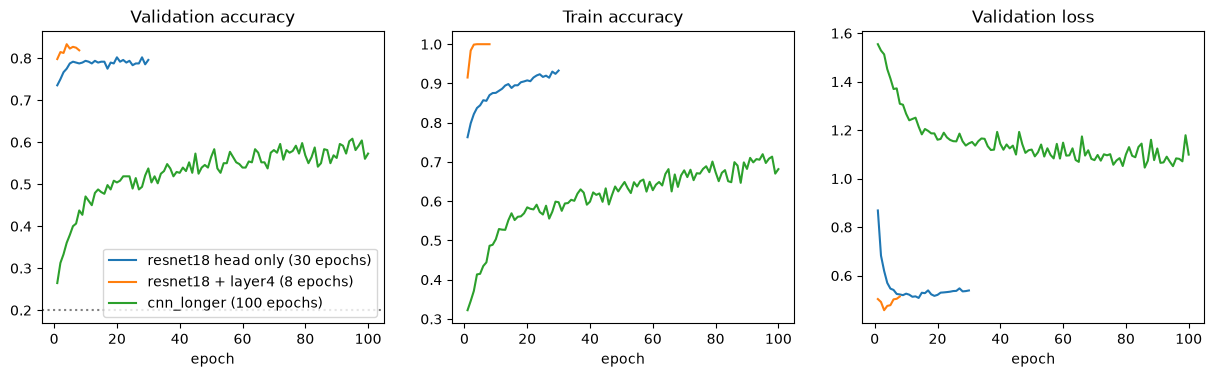

In [5]:
histories = {
    "resnet18 head only (30 epochs)": head["result"]["history"],
    "resnet18 + layer4 (8 epochs)": layer4["result"]["history"],
    "cnn_longer (100 epochs)": cnn_longer["history"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for label, h in histories.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(epochs, h["val_acc"], label=label)
    axes[1].plot(epochs, h["train_acc"], label=label)
    axes[2].plot(epochs, h["val_loss"], label=label)
axes[0].set_title("Validation accuracy")
axes[1].set_title("Train accuracy")
axes[2].set_title("Validation loss")
axes[0].axhline(0.2, color="grey", linestyle=":")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
plt.show()

## 5. The smoother measures

The best epoch flatters a model, so we also look at the last epoch, the mean of the last epochs, and the score at the epoch of
lowest validation loss (ADR 0008). The mean uses the last 10 epochs, or all epochs for the short fine-tuning run.

In [6]:
def measures(history):
    val = np.array(history["val_acc"])
    loss = np.array(history["val_loss"])
    last = min(10, len(val))
    return {
        "best epoch (%)": 100 * val.max(),
        "last epoch (%)": 100 * val[-1],
        f"mean of last {last} (%)": 100 * val[-last:].mean(),
        "at lowest val loss (%)": 100 * val[loss.argmin()],
        "train acc, last (%)": 100 * history["train_acc"][-1],
        "lowest val loss": loss.min(),
        "val loss, last": loss[-1],
    }


pd.DataFrame({label: measures(h) for label, h in histories.items()}).round(1)

,resnet18 head only (30 epochs),resnet18 + layer4 (8 epochs),cnn_longer (100 epochs)
best epoch (%),80.2,83.3,60.8
last epoch (%),79.6,81.9,57.3
mean of last 10 (%),79.1,NaN,58.8
at lowest val loss (%),79.0,81.2,58.3
"train acc, last (%)",93.3,100.0,68.2
lowest val loss,0.5,0.5,1.0
"val loss, last",0.5,0.5,1.1
mean of last 8 (%),NaN,81.9,NaN


## 6. All models side by side

Every run of the project, from `results/experiments.csv`, best validation score first. `val_acc_mean` and `val_acc_std` are over
several seeds when we ran them. `n_params` counts the trainable weights.

In [7]:
summary()[["name", "model", "image_size", "n_params", "epochs", "best_val_acc", "val_acc_mean", "val_acc_std"]]

,name,model,image_size,n_params,epochs,best_val_acc,val_acc_mean,val_acc_std
9,resnet18_layer4,resnet18,224,8396293,8,0.8333,NaN,NaN
10,resnet18_layer4,resnet18,224,8396293,8,0.8333,NaN,NaN
7,resnet18_head,resnet18,224,2565,30,0.8021,0.8033,0.0046
8,resnet18_head,resnet18,224,2565,30,0.8021,0.8033,0.0046
2,cnn_longer,cnn,64,23909,100,0.6083,NaN,NaN
4,cnn_longer_batchnorm,cnn,64,24133,100,0.5979,NaN,NaN
3,cnn_batchnorm,cnn,64,24133,30,0.5938,NaN,NaN
6,cnn_deeper_5seeds,cnn,64,98085,100,0.5896,0.5837,0.0112
5,cnn_deeper,cnn,64,98085,100,0.5896,NaN,NaN
1,cnn_first,cnn,64,23909,30,0.5375,0.5358,0.0079


## 7. By genre

In [8]:
confusions = {"cnn_longer": cnn_longer["val_confusion"], "resnet18_head": head["confusion"],
              "resnet18_layer4": layer4["confusion"]}
per_genre = pd.DataFrame({name: {genre: c.loc[genre, genre] / c.loc[genre].sum() for genre in c.index}
                          for name, c in confusions.items()}).round(2)
display(per_genre)
display(head["confusion"])
display(layer4["confusion"])

,cnn_longer,resnet18_head,resnet18_layer4
cityscape,0.65,0.76,0.76
landscape,0.61,0.80,0.88
portrait,0.61,0.80,0.79
religious_painting,0.59,0.72,0.79
still_life,0.57,0.93,0.95


predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,73,17,0,4,2
landscape,9,77,1,1,8
portrait,0,1,77,10,8
religious_painting,3,2,19,69,3
still_life,1,0,5,1,89


predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,73,18,0,3,2
landscape,6,84,0,2,4
portrait,0,0,76,7,13
religious_painting,3,3,13,76,1
still_life,0,1,3,1,91


## 8. Score on the test set (only when a model is final)

Museum B is used once per model (ADR 0003). Put the stage to score in `FINAL` (`"head"` or `"layer4"`), set `TEST_NOW` to `True`,
and run the cell once.

In [ ]:
TEST_NOW = False  # set to True only when the model is final, then run this cell once
FINAL = "head"  # which stage to score: "head" or "layer4"

if TEST_NOW:
    config, outcome = (HEAD, head) if FINAL == "head" else (LAYER4, layer4)
    test_data = load_resnet_data(config, splits=("test",))
    add_test_score(outcome["stem"], build_resnet_head(config), test_data)

resnet18_head_2026-10-22_17-09-51: test accuracy 84.5%, test loss 0.425 (written in results/experiments.csv)


In [ ]:
TEST_NOW = False  # set to True only when the model is final, then run this cell once
FINAL = "layer4"  # which stage to score: "head" or "layer4"

if TEST_NOW:
    config, outcome = (HEAD, head) if FINAL == "head" else (LAYER4, layer4)
    test_data = load_resnet_data(config, splits=("test",))
    add_test_score(outcome["stem"], build_resnet_head(config), test_data)

resnet18_layer4_2026-10-22_17-21-37: test accuracy 86.0%, test loss 0.423 (written in results/experiments.csv)


## What we see

| | trainable weights | validation (museum A) | test (museum B) |
|---|---|---|---|
| stage 1: frozen ResNet, new final layer | 2,565 | **80.3%** mean of 5 seeds (std 0.5; 79.8% to 81.0%); seed 0: best 80.2%, last epoch 79.6% | **84.5%** (test loss 0.425) |
| stage 2: last block also trained | 8,396,293 | 83.3% best epoch (epoch 4), 81.9% mean of its 8 epochs; one seed | **86.0%** (test loss 0.423) |
| for comparison: best small CNN (`cnn_longer`) | 23,909 | about 59% | not scored |

The test scores are those of the seed-0 model of each stage, scored once (ADR 0003).

- **Transfer learning gives about 20 points over our best CNN** on validation, with a stable result across seeds (std 0.5). Stage 1
  trains in about a second once the frozen features are computed. The genres the CNNs struggled with improved most (stage 1,
  validation): religious painting 34% to 72% and still life 42% to 93%.
- **Training the last block adds little.** On validation it is 2 to 3 points better on the smoother measures; on the test set 1.5
  points better, with the same test loss (0.423 against 0.425). With 600 test images (about +/- 3 points) this is no clear
  difference, and it costs 8.4 million trainable weights, 100% train accuracy and about 10 minutes against 1 second. At
  prediction time the two models are the same ResNet-18, so they cost the same to run.
- **The test score is higher than the validation score, not lower.** ADR 0003 feared a drop on artists the model never saw, and
  there is none: about +4 points for both stages. That is within the combined noise of the two sets, so we should not read much
  into the sign. Possible reasons, not tested: museum B only holds named, often famous artists, which may be easier than the
  "Unknown Artist" half of museum A. So there is no sign that the ResNets rely on recognising the painter, but this does not prove
  they would do as well in a real second museum.
- **Caveats.** The ResNet works at 224 px and our CNNs at 64 px, so part of the gain may be resolution rather than pretraining.
  No data augmentation. And since both stages were scored on museum B, the choice between them must not be made from those two
  test numbers (ADR 0003: museum B is not for model selection): we choose on validation and cost, and report both.

# Run validation with 3 seeds

In [13]:
layer4_3seeds = run_experiment("resnet18_layer4_3seeds", LAYER4, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=3)

8396293 parameters | before training: loss 1.877 (ln 5 = 1.609), accuracy 12.6%
epoch   1 | train loss 0.280 acc 0.915 | val loss 0.503 acc 0.798
epoch   5 | train loss 0.010 acc 1.000 | val loss 0.478 acc 0.823

best validation accuracy 83.3% at epoch 4 (432 s)
seed 1 (1 of 2 more): training, about 432 s...
   best validation accuracy 83.3% at epoch 8
seed 2 (2 of 2 more): training, about 432 s...
   best validation accuracy 83.3% at epoch 6
saved results/resnet18_layer4_3seeds_2026-10-23_09-36-32.pkl and added a row to results/experiments.csv


## What we see: the fine-tuning with 3 seeds

| | frozen ResNet-18 (stage 1) | last block also trained (stage 2) |
|---|---|---|
| seeds | 5 | 3 |
| best validation accuracy, per seed | 80.2, 80.2, 81.0, 80.4, 79.8 | 83.3, 83.3, 83.3 |
| mean | **80.3%** (std 0.5) | **83.3%** |
| difference | | **+3.0 points** |
| test accuracy (seed-0 model, scored once) | 84.5% | 86.0% |

- **The rule we wrote down before the run is met.** We said the fine-tuned model would be our final model if its 3-seed mean was clearly above
  the frozen 80.3% (more than about 2 points, ADR 0011). It is 3.0 points above. Since both cost the same at prediction time
  (P09: 70.3 ms against 70.5 ms), **the fine-tuned ResNet-18 at 224 px is our final model.** The price is on the training side only:
  about 10 minutes once, instead of 1 second, and 8.4 million trainable weights.
- **Do not report "std 0.0".** All three seeds reach exactly 83.33% (400 of 480 images). We checked that this is not a bug: the seeds do
  change the starting weights, the order of the images and the curves (validation accuracy at epochs 1 and 2: 79.8 and 81.5 for seed 0,
  79.6 and 80.2 for seed 1, 81.2 and 82.3 for seed 2). But the best epoch is a maximum over 8 noisy epochs, so the three maxima land on the
  same value, and this statistic hides the real variation between seeds (about 1 to 2 points at a given epoch).
- **The comparison is, if anything, unfair to the fine-tuned model:** the frozen model's best epoch is a maximum over 30 epochs, the
  fine-tuned one's over 8, so the frozen one has more chances to hit a lucky high value.
- **The test score is not new.** The model saved for the first seed is the very model that was already scored on museum B (identical
  weights and curves, checked), so its test accuracy stays 86.0%. The weights of seeds 1 and 2 are not saved, and the test set is not
  used to choose (ADR 0003). We chose on validation (480 images, about +/- 3.6 points), and the test scores point the same way (+1.5).
- It overfits (100% train accuracy) but its validation loss stays low (lowest 0.46, last 0.51).